# Project Final Report

### Due: Midnight on April 27th (2-hour grace period) — 50 points  

### No late submissions will be accepted.


## Overview

Your final submission consists of **two components**:


### 1. Team Final Report Notebook [50 pts]

Complete all sections of this notebook to document your final decisions, results, and broader context.

You will write a **technical report** following standard conventions. Useful references include:
- [CMU guide to structure](https://www.stat.cmu.edu/~brian/701/notes/paper-structure.pdf)
- [Data science report example](https://www.projectpro.io/article/data-science-project-report/620)
- The Checklist in this week’s Blackboard Lesson (aligned with HOML)

Your audience is **technically literate but unfamiliar with your work**—for example, your manager or other data scientists. Your report should be clear, precise, and well-organized, combining explanation, visualizations, and interpretation.

This Final Report is distinct from Milestone 2:

- **Milestone 2** serves as a repository of your working code and experiments  
- **This Final Report** presents a clear, structured summary of your project for a professional audience  

> **Important:**
> - Do **not** assume that readers of this report are familiar with Milestone 2. Your report should stand on its own.
> - Do not include full code or code cells in this notebook. All code was submitted in Milestone 2. This report should focus on explanation, results, and interpretation.
> - **Do not add, delete, or move cells in this notebook.** Each answer must be written entirely within its assigned Markdown cell.
> - All answers should be inserted directly under the appropriate `Answer:` prompt. Delete the sentence "Replace this sentence with your answer" and replace it with your response.
> - You may use any appropriate Markdown formatting (paragraphs, lists, tables, inserted graphics, LaTeX, etc.).
> - Submit this notebook as a group via your team leader’s Gradescope account.


### 2. Individual Assessment [0 points]

Each team member must **individually** complete the Final Project Individual Assessment Form (similar to Milestone 1), sign it, and upload it via their own Gradescope account.

**Due:** May 5th @ 2:00 AM



## Submission Checklist

- Final Report Notebook — submitted by team leader  
- Individual Assessment Form — submitted by each team member  



## 1. Executive Summary [4 pts]

Write a 300–400 word executive summary for a **non-technical audience**, such as business stakeholders in a real estate company.

Your summary should explain:
- the objective of the project
- key insights about the data
- the most important findings, including a plain-language description of model performance
- a clear recommendation or takeaway

Avoid technical detail and jargon. Focus on what matters and why.

**1.1 Answer:**  

The objective of our project is to train and produce a model to predict the value of any given property. The dataset utilized is a Zillow housing dataset that provides features such as square footage, number of rooms, latitude/longitude, and more. The utility of this model lies in the ability to identify when a property is being underevaluated. Underevaluated properties are a prime investment opportunity for this firm.

The Zillow housing dataset originally consisted of 54 features, but after EDA, we narrowed it to the 22 vital features. The most relevant features were related to property size and structure. This is intuitive and reflected in our preliminary analyses, as we know square footage and room count are primary drivers for prospective homeowners.

We trained and evaluated performance across three models. Our best model maximized accuracy without overfitting. This final model produced promising results, with the average prediction being within roughly 10–15% of the actual value for typical homes. These numbers may sound high, but our dataset primarily involved luxury homes, where scale was in the millions. Another note of significance: this model appears to underestimate on the higher end. All in all, we are confident in the model and believe it shows great promise with potential for improvement.

Our team's recommendation is to introduce the model into current workflows to test performance, continuously improve using new data, and refine our training processes. Limitations of the model cause the performance to change across different price ranges. The model should be used to assess where the user undervalues/overvalues properties and flag properties of note. Flagged properties would then be manually reviewed while the model is in its early stages. As performance improves, the amount of manual review should steadily decrease.

## 2. Introduction [3 pts]

Introduce the topic, context, and goals of your project.

You may imagine that this project was completed for a **real estate company with a small in-house data science team**.

Include all of the following:

- Clearly introduce the topic and context of your project
- Describe the problem you are addressing (the problem statement) and the overall motivation for solving it
- Clearly state the objectives and goals of your analysis (as different from the motivation)

**2.1 Answer:**  

In this project, we experimented with a Zillow housing dataset to train a model to predict a property's market value. In obtaining this information, we can compare our model predictions to actual prices to identify when a property has been underevaluated.

The problem we are addressing, predicting a property's market value, is challenging due to the large number of factors that play a role in the determination of this value. There are obvious features, such as square footage and room count, that correlate with value, but a model is needed to uncover less obvious predictors.

The goal of our project is to produce a deployable model capable of flagging undervalued properties at a level on par with or exceeding industry experts.

## 3. Data Description [3 pts]

Describe the dataset used in your analysis.

Include:
- the source of the dataset
- the number of observations (samples) and features
- the types of variables
- the target variable
- missing values or other important issues in the raw data

**3.1 Answer:**  

The dataset, a smaller version of the Zillow housing dataset used in Kaggle's 2017 Zillow Million Dollar Prize, contained residential property records and assessed home values. Each record represented one property and included features that could help predict home value. The target variable was taxvaluedollarcnt, the assessed tax value of each property.

The dataset included both numerical and categorical variables. Key numerical features described home size and structure, such as “finishedsquarefeet12, calculatedfinishedsquarefeet, bathroomcnt, bedroomcnt, and calculatedbathnbr”. Other variables captured property type or quality, while some were identifiers, offering little predictive value. After cleaning, the dataset contained 76,802 observations and 22 predictor features.

Several data issues had to be addressed before modeling. Many variables contained missing values, so incomplete features were removed or imputed. Some predictors were also redundant; multiple square footage and bathroom-related variables measured similar characteristics. In addition, the target variable was right-skewed and included extremely high-value homes, creating potential outlier problems. Overall, the dataset provided useful housing information, but careful cleaning and feature selection were necessary before building reliable models.

## 4. Methodology (What you did, and why) [20 pts]

Focus on the **process and your reasoning**, not the results.

Note: Each subsection (e.g., 4.1, 4.2, etc.) must be answered in its own Markdown cell.  Each subsection is worth 5 points.

### 4.1 Analytical Framework

Describe your overall approach.

Include:
- your overall framework
- use of validation curves
- choice of MAE or RMSE (as appropriate) as the primary error metric

**4.1 Answer:**  

The project followed a supervised machine learning workflow for regression. The overall approach was to explore and clean the Zillow data, prepare features for modeling, compare several regression models, tune the strongest model, and evaluate final performance on held-out data. The goal was to build a model that generalized well and predicted home values accurately.

Validation curves and cross-validation were used to compare model performance and monitor overfitting to choose the final model. These tools were especially helpful for tree-based models, where model complexity can increase quickly. By examining training and validation results, it was easier to identify when a model was too simple or too complex for the data.

The main error metric used for comparison was mean absolute error (MAE). MAE was selected because it is easy to interpret as the average dollar difference between predicted and actual home values. It was also a better primary metric than RMSE for this dataset because it is less affected by extreme high-value homes. RMSE was still considered as a secondary measure since it places more weight on large prediction errors.

### 4.2 Data Cleaning and Preprocessing

Describe how you prepared the data.

Include:
- issues in the raw data
- handling of missing values, outliers, inconsistencies
- key decisions and why
- what worked and what did not work

**4.2 Answer:**  

The raw Zillow data required substantial preprocessing before modeling. A major issue was missing data: some features were only partially populated, while others were missing so often that they would have introduced more noise than value. To address this, columns with excessive missingness (>65%) were removed, and remaining missing values were handled with imputation methods appropriate to the variable type. Numerical features were filled using central tendency methods (median), while categorical or encoded variables were handled using simple, consistent replacement rules. This allowed us to retain useful records without discarding too much data.


Another important issue was inconsistency and redundancy across related variables. For example, multiple columns captured similar information on home size or bathroom counts. Keeping every overlapping feature risked adding noise, multicollinearity, or unnecessary model complexity. Thus, preprocessing involved narrowing the feature set to the variables that were most interpretable and most predictive. Identifier-like fields and variables that did not contribute a meaningful signal (e.g., parcelid) were excluded from the final modeling set.


Outliers were also a challenge, especially among very high-value properties. These homes are real observations rather than data-entry errors, so they could not simply be deleted without affecting the dataset’s business meaning. Instead, we compared models and metrics with awareness that extreme values would make the problem harder and likely increase error on the upper end of the market. What worked well was removing weak or sparse columns, imputing missing values, and simplifying the feature space before training. What worked less well was removing identifier columns indisciminately based on judgement; unexpected columns, such as fips (Federal Information Processing Standards code) ended up being selected as important by the feature selection algorithm SelectKBest.

### 4.3 Feature Engineering

Describe your feature engineering.

Include:
- transformations or new features
- why you created them
- which were useful or not useful
- what worked and what did not work

**4.3 Answer:**  

The first new feature is finishedsquarefeetratio, the ratio between finished living area square footage and total finished living area square footage - chosen to see how impactful the ratio between finished living room space and the total finished living room space was, since they had very high F-scores. Next is yeardiff, the difference between assessment year and year the building was built, chosen to derive greater importance than the features separately. Third was spatial_density, a measure calculated using latitude, longitude to determine the amount of nearby buildings, chosen after seeing a proof-of-concept in an article on a Miami housing dataset.

The first three features failed to improve performance signficantly, informing the team to perhaps pick and combine less closely related features. For revision, we used space_room_ratio, the ratio between finished living area square footage and number of bathrooms, including fractional bathrooms, chosen to find the impact of bathrooms rather than introducing potential redundance with finishedsquarefeetratio. Room_unit_sum, the sum of rooms in the unit and units in the building, was chosen to see if a more holistic view on property value was needed by accounting for the whole building. Polar latitude and longitude were calculated to see if the conversion made the features more important. The last new feature added was haversine, which calculates the great circle distance between a point on Earth and the (0, 0) lat-long coordinate, chosen after research on location feature engineering.

Findings: Improvement derives more from feature selection than engineering. Removing the redundant features or features with almost no unique values / variance in values resulted in more improvement than feature engineering. The space-room ratio and polar coordinates were selected as important in the linear model. The room unit sum was selected as important in the decision tree model. The other features did not work as they did not notably improve performance, and none were in the top 13 important features in the final model (Random Forest).

### 4.4 Model Selection

Describe how you selected your model.

Include:
- models you tried and why
- how you evaluated generalization
- hyperparameter tuning
- how you chose the final model

**4.4 Answer:**  
Models tried were Ridge Regression, Decision Tree Regressor, and Random Forest. These models were chosen for interpretability, performance, and variety, since Random Forest is an ensemble model. Generalization was evaluated by examining the MAEs and MAE standard deviation, and plotting the results to visualize overfitting or underfitting.

**Hyperparameter Tuning Strategies**\
*Ridge Regression*\
Best parameters: an alpha of 1000.
For tuning the hyperparameters for linear regression we first had to pivot specifically to ridge regression so as to introduce a hyperparameter, *alpha*, referring to the regularization strength. Using GridSearchCV, we could quickly sweep a large range.\
Feature engineering, as well as scaling, was especially relevant with this ridge regression model, so that each feature was considered fairly regardless of its magnitude.

*Decision Tree Regressor*\
Best parameters: maximum tree depth of 20, no limit to amount of features, minimum samples for a tree leaf of 8, and minimum samples to split a tree of 2. \
Our decision tree model already had hyperparameters we could tune, such as max_depth, min_samples_split, min_samples_leaf, and max_features. We could once again use GridSearchCV to test these parameters.\
Feature Engineering is relevant in our decision tree model, by providing *shortcuts* for the tree through bonus features such as `space_room_ratio` so the tree does not have to derive that relationship itself.

*Random Forest*\
Best parameters: 200 tree estimators, minimum samples for a tree leaf of 2, and minimum samples to split a tree of 2, half the total number of features as the max, and maximum tree depth of 20.\
Random Forest has a much larger search space than the other models, requiring compromises in hyperparameter tuning. The paramters tuned were n_estimators, max_depth, min_samples_split, min_samples_leaf, and max_features. For efficiency reasons due to limited compute, we reduced the number of iterations and made educated guesses on parameters prior to running using the parameter sweeping in prior coursework, which yielded diminishing returns over 20 maximum trees.\
Random forest receives similar benefits from feature engineering as our decision tree model. The bonus features increase the total amount of information usable by our decision trees.\

The final model selected was Random Forest Regressor because it had the best overall performance on the training data, as explained in section 5.1.

## 5. Results and Evaluation (What you found, and how well it worked) [16 pts]

Focus on **results, evidence, and interpretation**.

Note: Each subsection (e.g., 5.1, 5.2, etc.) must be answered in its own Markdown cell.

### 5.1 Model Performance (6 points)

Briefly interpret what your metrics mean in practical terms.

Include:
- key metrics (e.g., RMSE, $R^2$)
- comparison across models
- comparison of training vs validation/test performance

**5.1 Answer:**  
The evaluation metric of choice for the models was mean absolute error (MAE), the average absolute difference between predictions and true values. It is in the same units as the inputs (i.e., 1000 MAE would represent \$1000 off) and is resistant to outliers. We also used $R^2$ (a measure of explaining variance) for the final model. Performance on base models via cross-validation or CV MAE mean and standard deviation (average of error and spread relative to mean error): Linear Regression CV MAE Score was ~194176.28 and CV MAE Standard Deviation was ~1208.02. DecisionTreeRegressor CV MAE Score was ~217197.87 and CV MAE Standard Deviation was ~2156.47. RandomForestRegressor CV MAE Score was ~165840.44 and CV MAE Standard Deviation was ~1176.


The regression models did not perform equally well. Linear Regression provided a useful baseline, but its performance was weaker because the relationships in the housing data were not purely linear. The Decision Tree captured more complexity, but was more likely to overfit the training data. Among the models tested, Random Forest had the best overall results because it handled nonlinear relationships well and reduced overfitting by combining many decision trees. The stronger performance was also consistent with the data structure, in which housing value depended on multiple interacting features such as square footage, number of bathrooms, and property quality.



The final model selected was Random Forest Regressor, with a CV MAE mean of \$167,362.58 and a CV MAE standard deviation of \$1,137.74. It produced an $R^2$ score of 0.56, indicating that it explains approximately 56% of the variance in assessed property values, a moderate performance that reflects the complexity and noise inherent in real-world housing data. These results showed that it was both the most accurate (lowest mean = lowest on average) and the most stable (lowest standard deviation = least variance) of the three models. The final model had a test MAE of \$167,804.97, which is the performance against the set held out from the data. There is only a 2.6% difference between the training and test performance, showing that the model generalizes well. In context, the model can predict the total assessed value of a property with an average error of \$167,804.97, and the CV scores are stable across folds (std = \$1,137).

### 5.2 Visualizations (5 points)

Graphics should be made as screenshots and dragged into the Markdown cell. Do NOT add code cells to create graphics. Each visualization must be clearly labeled and explained in the text.

Include:
- relevant plots with titles and labels
- explanation of what each plot shows
- why each visualization matters

**5.2 Answer:**  
*Plot 1:* \
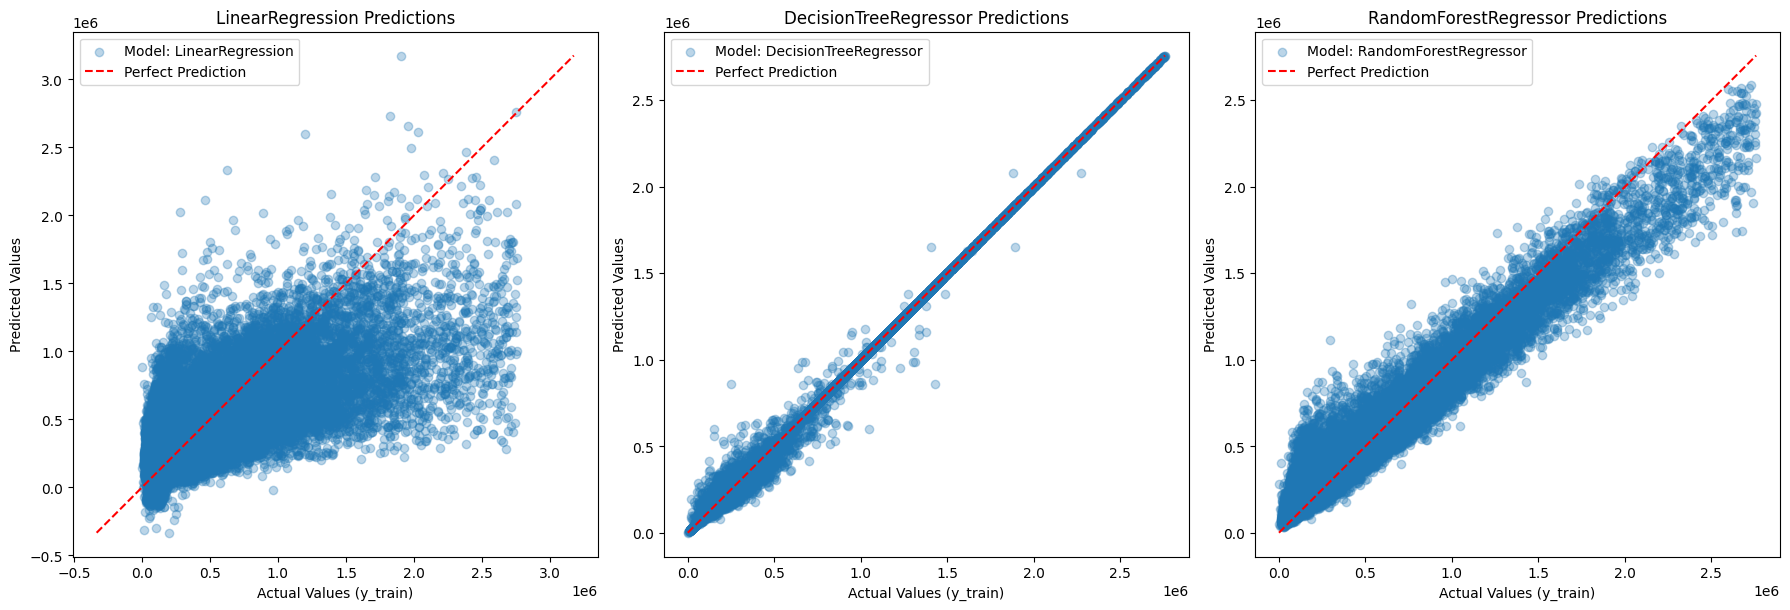
This plot shows the predictions for all three models for the project on the training data. Based on the prediction charts, the Decision Tree Regressor shows signs of memorization for values > $1M, while Linear Regression shows signs of underfitting as it predicted somewhat poorly. If an investor is most concerned with consistently predicting property value to make a profit, this visualization would prompt them to choose the Random Forest Regressor.\
*Plot 2:*\
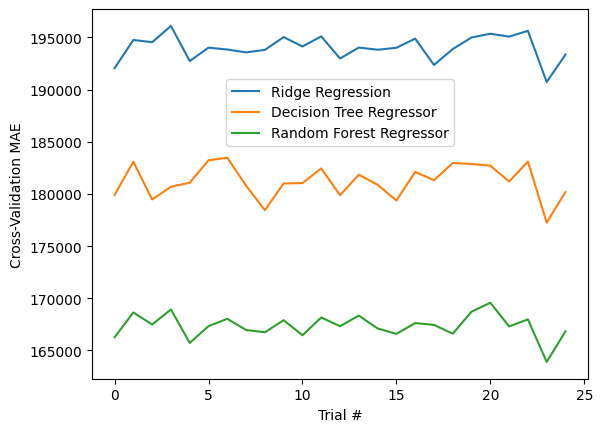\
This plot shows the cross-validation MAE for all three models. While their shapes are simple, it's clear what models predict the best, and you can see how the Decision Tree Regressor has slightly more variance than the rest. This visualization matters to investors looking to choose which model fits the market. Furthermore, market volatility already hampers predictions, so the model variance shown in the visual would further compound the difficulties in predicting market value.\
*Plot 3:*\
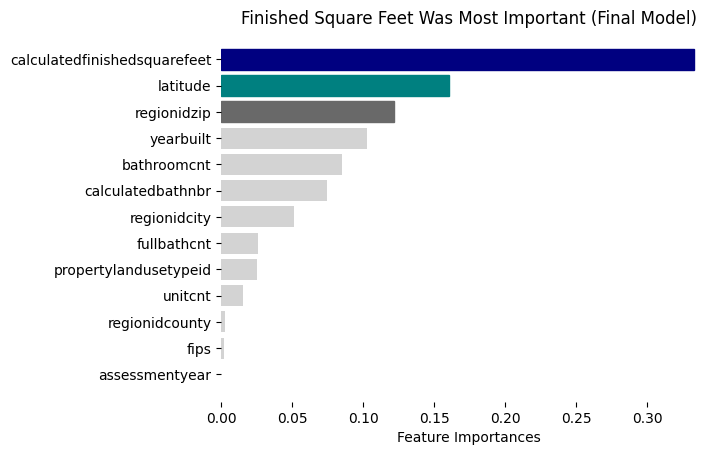\
This plot shows the feature importances for the final tuned model. You can see major importance placed on the property's square footage, but the next two standout features are both related to location, making the significance of space and location about even in determining market value. You can also see that region ID, county, fips, and assessment year have almost no feature importance, making it easier for an investor experimenting with the model to treat them as less important in assessing the market value of a property.\
*Plot 4:*\
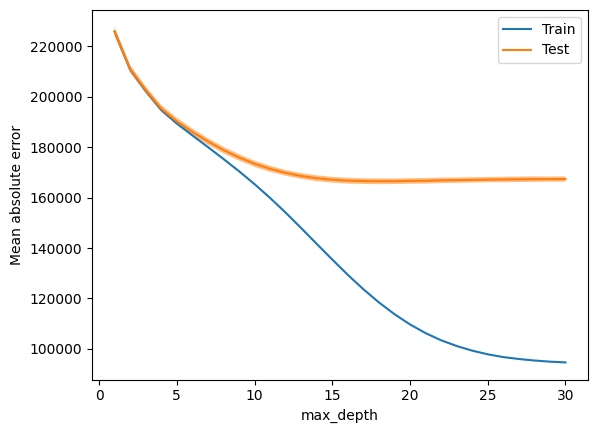\
This plot shows the final model's validation curve. As the tree gets deeper and evaluates more splits, the training and test errors decrease to a stable plateau. The similarity in shape shows the lack of bias and overfitting. This visualization shows that the model is effective for predicting the value of new properties outside the scope of the dataset. The model would be useless in practice if the gap were too wide.\
*Plot 5:*\
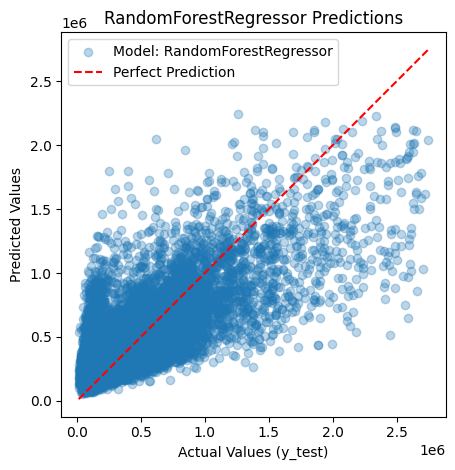\
This plot shows the final model's predictions on the test set compared to the ground truth. It's important to get a view of what the patterns are relative to the true data, apart from the (absolute) residuals. If the investor has a threshold for underprediction, they may hesitate to use this model, whereas if they have one for overprediction, the plot shows little to no concern should be placed on that in predicting property value.

_Plot 6:_

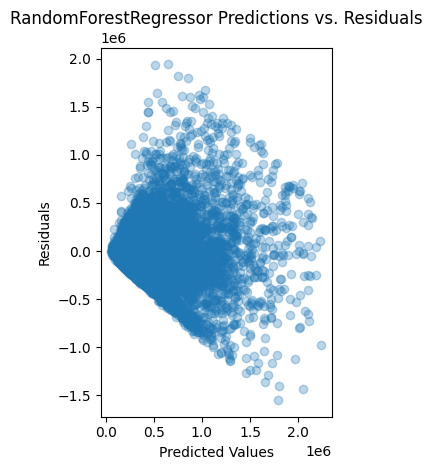

This plot shows predicted values on the test set vs. the difference between predictions and actual values (residuals). This visual is important because it can show a business user the underpredicting tendencies and inform their investment strategy.

### 5.3 Error Analysis (5 points)

Include:
- patterns in residuals or prediction errors
- overprediction or underprediction
- outliers or unusual observations
- anything surprising or worth improving

**5.3 Answer:**  
The models were very consistent in their residuals. Based on Plot 6, the final model tended to underpredict on property value rather than overpredict, as the errors were larger for high-value properties. The shape of the plot exemplifies heteroscedasticity: variance in errors grows with property value. Very high-value properties (above \$1.5M or \$2M) appear to have consistently large residuals. Unexpected: the nonlinear nature of the data suggests that the decision tree regressor would predict better than the linear regression model with less bias, but it ends up reading too much noise and overfitting. Another unusual observation was the random forest regressor performing slightly worse in CV mean absolute error with feature engineering and hyperparameter tuning, but the standard deviation continuously got lower with these adjustments, suggesting the added features introduced mild noise while stabilizing predictions across folds. Investigation implied that the random forest regressor was best in CV MAE with more of the original features, perhaps due to the randomness aspect, but the team is uncertain.

## 6. Conclusion [4 pts]

Summarize your findings and implications.

Include all the following:

- Clearly state your main findings and how they address your original objectives
- Highlight any business or practical implications of your findings
- Discuss the limitations and constraints of your analysis clearly and transparently
- Suggest potential improvements or future directions
- Conclude with a final recommendation addressing the business objective

**6.1 Answer:**  
The final tuned model Random Forest Regressor captures complex relationships in the Zillow housing data to predict the value of a property with an average error of $167,804.97 on a scale of millions. This makes the model capable of identifying undervalued properties for the purpose of investment, though the model's tendency to underpredict should be accounted for in any investment decision. Practical implications: unit space is most important and matters more than bedroom/bathroom/room counts in predicting property value. It's easier to predict the value of a lower-value property than a higher-value property, likely due to the scarcity.

Limitations and constraints: the features created during feature engineering provided minuscule improvement on their own, as feature selection helped more than engineering. No model fit both typical homes and luxury properties equally well; the final results suggest that the upper tail of the market remained the hardest part of the prediction problem. None of the group members has extensive domain knowledge in topography or its relation to statistics. The team had limited collaborative compute on Google Colab and power/time individually to run long cross-validation sweeps, and could have tuned more effective models using more estimators or parameters, including minimum impurity decrease. The data also lacks other cultural factors that drive up property value, such as the presence of landmarks, tourist attractions, and public transit.

Potential improvements could come from engineering other, more sophisticated geo-based features such as geo-hashing, basing the locations on distance to city centers, or converting the values into different units, i.e., radians. With more time spent breaking down zip code, latitude, and longitude, the team could engineer features that better define their relationship with property value in the dataset, see the influence of location, and improve prediction. Furthermore, coupling the stronger neighborhood or location-based features with a Gradient Boosting estimator and using an ensemble of boosting and bagging could produce even less biased predictions. Another improvement would be made by scoping the relevance of the year built, the third most important feature to the model. The linear transformation of year built with assessment year was an unimpactful feature. More feature engineering could reveal how the year a building was built, combined with other factors, drives value.

Overall, the findings suggest that home value prediction benefits from both data preparation and the use of models capable of handling complex patterns. Housing data has nonlinear patterns that ensemble tree models handle well, and the team would recommend the prioritization of calculated square feet and latitude to evaluate how undervalued a property is. This addresses our objective of training and producing a model to predict the value of any given property, alleviating the work of real estate investors and agents. The results were meaningful not only for comparing algorithms, but also for understanding which housing characteristics had the greatest influence on assessed property value.